# TP4 : Architecture Transformer

## 1. Génération du dataset
Série temporelle `s = sin(x)` : 200 valeurs entre 0 et 20, rangées en séquences de dimension 10. Chaque séquence `X` prédit la valeur suivante `Y`.

In [1]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

torch.manual_seed(42)

# 200 valeurs de sin(x) entre 0 et 20
periode = torch.linspace(0, 20, 200)
serie = torch.sin(periode)

# Séquences de dimension 10 : X = [s0..s9], [s1..s10], ... ; Y = [s10], [s11], ...
longueur_sequence = 10

X = torch.stack([
    serie[i:i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])
y = torch.stack([
    serie[i + longueur_sequence]
    for i in range(len(serie) - longueur_sequence)
])

# Forme attendue par les modèles : (nombre de séquences, longueur, 1)
X = X.unsqueeze(-1)
y = y.unsqueeze(-1)

# Découpage chronologique : début pour apprendre, fin pour tester
X_train, y_train = X[:150], y[:150]
X_test, y_test = X[150:], y[150:]

print("X :", X.shape)
print("y :", y.shape)
print("X_train :", X_train.shape, "| X_test :", X_test.shape)
print("Premier exemple X :", X[0].squeeze().tolist())
print("Premier exemple Y :", y[0].item())

X : torch.Size([190, 10, 1])
y : torch.Size([190, 1])
X_train : torch.Size([150, 10, 1]) | X_test : torch.Size([40, 10, 1])
Premier exemple X : [0.0, 0.10033340752124786, 0.199654221534729, 0.29696008563041687, 0.39126893877983093, 0.48162901401519775, 0.5671283602714539, 0.6469041109085083, 0.7201511263847351, 0.7861301898956299]
Premier exemple Y : 0.8441754579544067


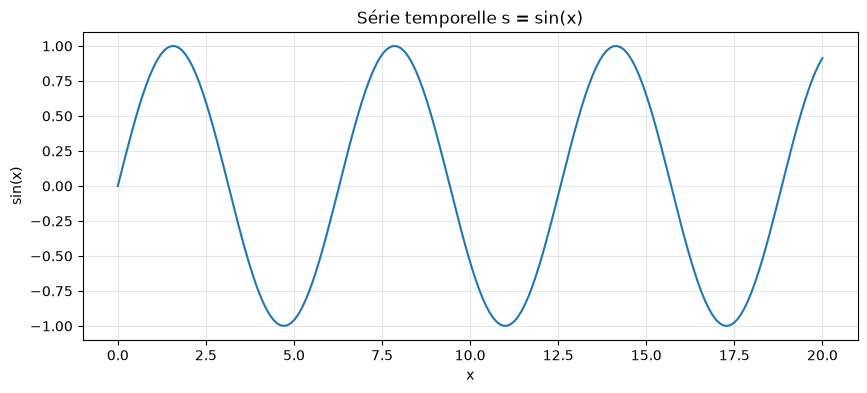

In [2]:
plt.figure(figsize=(10, 4))
plt.plot(periode, serie)
plt.title("Série temporelle s = sin(x)")
plt.xlabel("x")
plt.ylabel("sin(x)")
plt.grid(True, alpha=0.3)
plt.show()